# Assignment 11: Spatial community composition — blobs or stripes?

### **This is an imaginary exercise.**

Maine can protect **1,000 km²** as two compact **blob** parks or two long,
narrow **stripe** parks. Each park covers 500 km². Which design would you
recommend for conserving amphibian diversity?

Follow the analyses in [Lab10](../labs/Lab10-CommunityComposition.ipynb), now
comparing park shapes. You may reuse its code and functions. Complete the code cells 
and short answers. Submit this notebook with its maps, tables, and saved summary CSVs.

## The data

[`ME_BlobStripeParks.geojson`](../data/ME_BlobStripeParks.geojson) contains two
roughly round blobs and two elliptical stripes, five times as long as they
are wide. All four are imaginary, nonoverlapping, and within Maine and the
source sample bounds. Each point already has a park assignment.

Sampling follows Lab10. All real records inside these parks are retained.
All source records in `amphibians.geojson` determine each observed species'
convex hull, its 50 km buffer, and its record-count weight. Each of **50 invented
species** inherits the buffered range and abundance weight of a randomly
sampled observed species. Added points are sampled within those ranges'
intersections with the parks, with counts proportional to the observed or
inherited weights. One point per invented species is reserved. There are
**1,500 total points**, including originals; seed = 597.

`synthetic` identifies generated points; `imaginary_species` identifies invented
taxa.

## 1. Import packages and load the data

Run from `docs/assignments` using the same environment as Lab10.

In [12]:
from pathlib import Path

import geopandas as gpd
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import entropy
from scipy.spatial.distance import jaccard, braycurtis

AREA_CRS = "EPSG:5070"
COLORS = {"blob": "forestgreen", "stripe": "darkorange"}
designs = ["blob", "stripe"]

In [13]:
features = gpd.read_file("../data/ME_BlobStripeParks.geojson")
parks = features[features.feature_type == "park"].copy()
parks = parks.to_crs(AREA_CRS).set_index("park_id")
records = features[features.feature_type == "occurrence"].copy().to_crs(AREA_CRS)
park_order = list(parks.index)

display(parks[["park_name", "scenario", "area_km2"]])
print("Total occurrence records:", len(records))

print(parks.columns.tolist())

,park_name,scenario,area_km2
park_id,,,
B1,Alder Crown Preserve,blob,500.0
B2,Hemlock Hollow Reserve,blob,500.0
S1,Fern Ribbon Preserve,stripe,500.0
S2,Silver Brook Reach,stripe,500.0


Total occurrence records: 1500
['feature_type', 'gbifID', 'occurrenceID', 'species', 'decimalLongitude', 'decimalLatitude', 'coordinateUncertaintyInMeters', 'synthetic', 'imaginary_species', 'donor_species', 'record_source', 'year', 'park_name', 'scenario', 'area_km2', 'center_lon', 'center_lat', 'fictional', 'geometry']


## 2. Map the parks and check the comparison

Map the four polygons and their points, using one color per design. Label the
park IDs. A simple map is enough.

Calculate area in km² and show the total area and number of occurrence records
for each design. Keep all records, including generated points and invented
species, in the analyses below.

scenario
blob      1000.000589
stripe    1000.000753
Name: measured_km2, dtype: float64

scenario
blob      2
stripe    2
dtype: int64

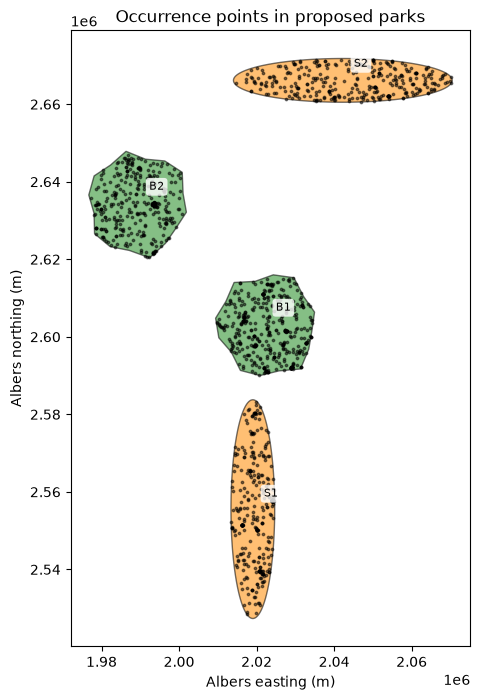

In [14]:
parks["measured_km2"] = parks.area / 1e6
display(parks.groupby("scenario").measured_km2.sum())

# Count records in each design with records.groupby("scenario").size().
display(parks.groupby("scenario").size())

# Plot the parks and occurrence points; label B1, B2, S1, and S2.
fig, ax = plt.subplots(figsize=(8, 8))
for strategy, group in parks.groupby("scenario"):
    group.plot(ax=ax, color=COLORS[strategy], alpha=0.55, edgecolor="black")

records.plot(ax=ax, color="black", markersize=3, alpha=0.5)

# Annotate parks by name
for row in parks.itertuples():
    anchor = row.geometry.representative_point()
    ax.annotate(f"{row.Index}", (anchor.x, anchor.y),
                xytext=(8, 10), textcoords="offset points", fontsize=8,
               bbox=dict(boxstyle="round,pad=0.3", facecolor="white", edgecolor="none", alpha=0.8))

ax.set(title="Occurrence points in proposed parks",
       xlabel="Albers easting (m)", ylabel="Albers northing (m)")
plt.show()


**Interpretation:** What is held equal between the designs? What differs besides
shape? Predict which design will capture more species, and explain why.

*Your answer:*
The areas and shapes are the same, but the placement in space and orientations are different. I expect that the stripe design will capture more species because (depending on orientation) I would expect them to capture more of a cross-section of environmental gradients. 

## 3. Build the community matrix

Rows are parks; columns are species; entries are record counts. A zero means
no records of that species in that park. It does not establish true absence.

species,Ambystoma laterale,Ambystoma maculatum,Anaxyrus americanus,Aquarana clamitans,Aquarana septentrionalis,Boreorana sylvatica,Desmognathus fuscus,Dryophytes versicolor,Eurycea bislineata,Fictotriton alderi,...,Sylvophantoma glacialina,Sylvophantoma hazelii,Sylvophantoma inverna,Sylvophantoma kettleii,Sylvophantoma lichenosa,Sylvophantoma mapleii,Sylvophantoma noctiluca,Sylvophantoma sprucea,Sylvophantoma willowii,Sylvophantoma zephyra
park_id,,,,,,,,,,,,,,,,,,,,,
B1,1,15,47,38,0,37,0,21,1,0,...,0,0,0,3,4,2,1,0,0,8
B2,1,17,39,21,0,26,3,11,5,0,...,0,0,1,5,5,8,0,1,1,5
S1,0,5,47,18,0,22,3,18,6,0,...,1,0,0,2,3,2,0,0,1,5
S2,1,7,11,19,1,13,0,11,4,1,...,0,1,0,3,10,5,1,1,0,8


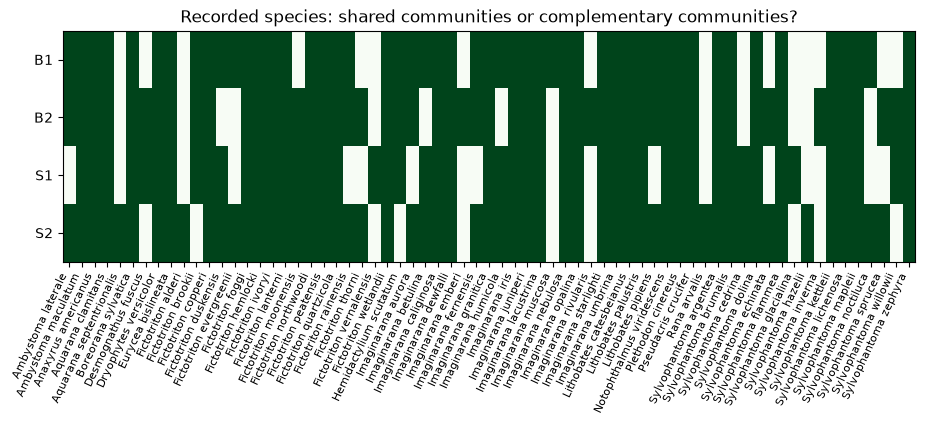

In [15]:
community = pd.crosstab(records.park_id, records.species)
community = community.reindex(park_order, fill_value=0)
presence = community > 0

display(community)

# Recreate distribution plot
fig, ax = plt.subplots(figsize=(11, 3))
image = ax.imshow(presence.astype(int), aspect="auto", cmap="Greens", vmin=0, vmax=1)
ax.set(yticks=range(len(community)), yticklabels=community.index,
       xticks=range(len(community.columns)), xticklabels=community.columns,
       title="Recorded species: shared communities or complementary communities?")
plt.setp(ax.get_xticklabels(), rotation=65, ha="right", fontsize=8)
plt.show()

How many species occur in the whole dataset? Choose one species and describe
its distribution among the four parks using its column in `community`.

*Your answer:*
There are 67 species in the whole dataset. The species Aquarana septentrionalis is only present in the S2 park. 

## 4. Richness, Shannon diversity, and evenness

Use the lab's function below. Shannon uses `scipy.stats.entropy`; larger values
reflect more species, greater evenness, or both.

In [16]:
def diversity(community_counts):
    results = pd.DataFrame(
        index=community_counts.index,
        columns=["n_records", "richness", "shannon"],
        dtype=float,
    )
    for unit, counts in community_counts.iterrows():
        species_present = counts[counts > 0]
        results.loc[unit, "n_records"] = counts.sum()
        if len(species_present) == 0:
            continue
        results.loc[unit, "richness"] = len(species_present)
        results.loc[unit, "shannon"] = entropy(species_present)
    return results

,n_records,richness,shannon,park_name,scenario,evenness
park_id,,,,,,
B1,436.0,51.0,3.323911,Alder Crown Preserve,blob,0.544485
B2,409.0,54.0,3.516299,Hemlock Hollow Reserve,blob,0.623327
S1,328.0,49.0,3.320299,Fern Ribbon Preserve,stripe,0.564666
S2,327.0,57.0,3.711955,Silver Brook Reach,stripe,0.718136


<class 'pandas.DataFrame'>


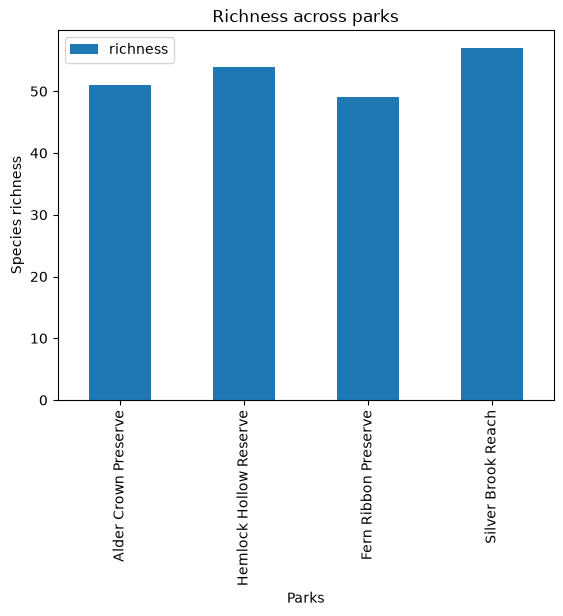

In [17]:
# Calculate park_metrics = diversity(community).
park_metrics = diversity(community)
# Add park names and scenarios from parks.
park_metrics["park_name"] = parks.park_name
park_metrics["scenario"] = parks.scenario
# Add evenness = np.exp(shannon) / richness, as in Lab10.
park_metrics["evenness"] = np.exp(park_metrics["shannon"])/park_metrics["richness"]
# Display the table and make a simple richness or Shannon plot.
display(park_metrics)
print(type(park_metrics))

# Richness plot
park_metrics.plot.bar(x = "park_name", y = "richness")
plt.title("Richness across parks")
plt.xlabel("Parks")
plt.ylabel("Species richness")
plt.show()


Does the richest park also have the highest Shannon diversity and evenness?
What would adding 100 records of an already common species do to these measures?

*Your answer:* The richest park also has the highest Shannon diversity and evenness. Adding 100 records of an already common species wouldn't change richness but would change evenness and Shannon diversity. 

## 5. Alpha, beta, and gamma diversity

Pool the two blob parks, then the two stripe parks. For each design, calculate:

- **Alpha:** mean richness of its two parks.
- **Gamma:** richness in the pooled species list.
- **Multiplicative beta:** gamma divided by alpha.
- Total records and pooled Shannon diversity.

Keep the park rows in `community`; use `design_counts` for the pooled rows.

In [18]:
design_counts = pd.DataFrame(index=designs, columns=community.columns, dtype=float)
for design in designs:
    park_ids = parks[parks.scenario == design].index
    design_counts.loc[design] = community.loc[park_ids].sum()

# Use diversity(design_counts) to start design_metrics.
design_metrics = diversity(design_counts)
# Rename its richness column to gamma_richness.
design_metrics = design_metrics.rename(columns={"richness": "gamma_richness"})
# For each design, find its two rows in park_metrics.
# Calculate mean_park_alpha and beta_ratio, then display design_metrics.
for design in designs:
    local_parks = park_metrics[park_metrics.scenario == strategy]
    alpha = local_parks.richness.mean()
    gamma = design_metrics.loc[strategy, "gamma_richness"]
    design_metrics.loc[design, "mean_park_alpha"] = alpha
    design_metrics.loc[design, "beta_ratio"] = gamma / alpha
    design_metrics.loc[design, "sum_park_richness"] = local_parks.richness.sum()
    design_metrics.loc[design, "area_km2"] = parks[parks.scenario == strategy].measured_km2.sum()
display(design_metrics)




,n_records,gamma_richness,shannon,mean_park_alpha,beta_ratio,sum_park_richness,area_km2
blob,845.0,60.0,3.460793,53.0,1.188679,106.0,1000.000753
stripe,655.0,63.0,3.606102,53.0,1.188679,106.0,1000.000753


Which design has higher gamma diversity? Does alpha or complementarity between
its two parks help explain the result? Why is pooled richness generally smaller
than the sum of the two park richnesses?

List species recorded only in blobs and species recorded only in stripes.
Hint: make a `set` from the species with positive counts in each pooled row;
subtract one set from the other.

*Your answer:*
Gamma diversity is higher in the stripe design. Mean park alpha is the same between the two designs (I am not sure what is meant by complementarity between parks). Pooled richness is generally smaller than the sum of park species richnesses, because species are counted multiple times when species richnesses are summed but only counted once when species richnesses are pooled. 

In [19]:
display(design_counts)

species,Ambystoma laterale,Ambystoma maculatum,Anaxyrus americanus,Aquarana clamitans,Aquarana septentrionalis,Boreorana sylvatica,Desmognathus fuscus,Dryophytes versicolor,Eurycea bislineata,Fictotriton alderi,...,Sylvophantoma glacialina,Sylvophantoma hazelii,Sylvophantoma inverna,Sylvophantoma kettleii,Sylvophantoma lichenosa,Sylvophantoma mapleii,Sylvophantoma noctiluca,Sylvophantoma sprucea,Sylvophantoma willowii,Sylvophantoma zephyra
blob,2.0,32.0,86.0,59.0,0.0,63.0,3.0,32.0,6.0,0.0,...,0.0,0.0,1.0,8.0,9.0,10.0,1.0,1.0,1.0,13.0
stripe,1.0,12.0,58.0,37.0,1.0,35.0,3.0,29.0,10.0,1.0,...,1.0,1.0,0.0,5.0,13.0,7.0,1.0,1.0,1.0,13.0


In [20]:
# Make blob_species and stripe_species from design_counts.
blob_counts = design_counts.loc["blob"]
stripe_counts = design_counts.loc["stripe"]
blob_species = set(blob_counts[blob_counts > 0].index)
stripe_species = set(stripe_counts[stripe_counts > 0].index)

# Print species unique to each design.
print("Only in the blob parks:", sorted(blob_species - stripe_species))
print("Only in the stripe parks:", sorted(stripe_species - blob_species))
print("In both strategies:", len(blob_species & stripe_species))

Only in the blob parks: ['Imaginarana emberi', 'Imaginarana muscosa', 'Imaginarana rivularis', 'Sylvophantoma inverna']
Only in the stripe parks: ['Aquarana septentrionalis', 'Fictotriton alderi', 'Fictotriton vernalensis', 'Rana arvalis', 'Sylvophantoma cedrina', 'Sylvophantoma glacialina', 'Sylvophantoma hazelii']
In both strategies: 56


### Jaccard dissimilarity

Jaccard compares presence/absence: 0 means identical species lists; 1 means no
shared species. Use `scipy.spatial.distance.jaccard` on rows of `presence`.

In [37]:
print("B1 versus B2:", jaccard(presence.loc["B1"], presence.loc["B2"]))
print("S1 versus S2:", jaccard(presence.loc["S1"], presence.loc["S2"]))

# Build jaccard_distances, a four-by-four table, as in Lab10.
# Use nested loops over park_order and jaccard(presence.loc[a], presence.loc[b]).
# For loop calculates Jaccard distance between given park and every other park
jaccard_distances = pd.DataFrame(index=park_order, columns=park_order, dtype=float)
for park_a in park_order:
    for park_b in park_order:
        jaccard_distances.loc[park_a, park_b] = jaccard(
            presence.loc[park_a], presence.loc[park_b]
        )
# Display the table.
display(jaccard_distances.round(2))

# Jaccard dissimilarity of 0 means identitical species, 1 is completely different species composition

B1 versus B2: 0.25
S1 versus S2: 0.31746031746031744


,B1,B2,S1,S2
B1,0.00,0.25,0.25,0.20
B2,0.25,0.00,0.28,0.27
S1,0.25,0.28,0.00,0.32
S2,0.20,0.27,0.32,0.00


Compare B1–B2 with S1–S2. Which design's two parks have more different species
lists? Does that agree with the beta ratios? Explain why Jaccard alone cannot
distinguish species replacement from differences in richness.

*Your answer:*
Species are more different between S1 and S2, which is different from the beta ratios (equal across park types). Jaccard alone can't distinguish species replacement from differences in richness because it is combining species richness with differences in species (turnover). 

### Bray–Curtis dissimilarity

Use `scipy.spatial.distance.braycurtis` on record counts. Make a second
four-by-four table, `bray_curtis_distances`.

Then repeat the B1–B2 and S1–S2 comparisons using **relative frequencies**:
divide each park's species counts by its total records before calling
`braycurtis`.

In [36]:
print("B1 versus B2:", braycurtis(community.loc["B1"], community.loc["B2"]))
print("S1 versus S2:", braycurtis(community.loc["S1"], community.loc["S2"]))

# Build and display bray_curtis_distances using the Jaccard loop pattern.
# For each within-design pair, divide each row by its sum and compare again.
bray_curtis_distances = pd.DataFrame(index=park_order, columns=park_order, dtype=float)
for park_a in park_order:
    for park_b in park_order:
        bray_curtis_distances.loc[park_a, park_b] = braycurtis(
            community.loc[park_a], community.loc[park_b]
        )
display(bray_curtis_distances.round(2))


B1 versus B2: 0.19763313609467456
S1 versus S2: 0.30381679389312977


,B1,B2,S1,S2
B1,0.00,0.20,0.24,0.33
B2,0.20,0.00,0.25,0.27
S1,0.24,0.25,0.00,0.30
S2,0.33,0.27,0.30,0.00


Do Jaccard and Bray–Curtis tell the same story? What information does Bray–Curtis
add? Why can unequal record totals affect its values, and what changes when
you use relative frequencies?

*Your answer:* Bray-Curtis finds greater difference between parks S2 and B1, and Jaccard found the greatest difference between S1 and S2 (second highest by BC). When you use relative frequencies, as in Bray-Curtis, species are weighted by abundance rather than using binary as in Jaccard - so species with fewer total records contribute less and species with more records contribute more. Bray-Curtis is less sensitive to rarer species. 

## 6. Compare equal numbers of records

Use record-based rarefaction to check whether the pooled richness comparison
persists when both designs contribute the same number of records. Draw without
replacement and repeat **300 times**, following the lab's loop.

For each design, report mean richness and the 2.5th and 97.5th percentiles of
the draws. These percentiles describe resampling variation, not confidence
intervals for true richness. Equal record counts do not establish equal survey
effort or detectability.

In [27]:
equal_n = records.groupby("scenario").size().min()
rarefaction = pd.DataFrame()

# For each design, select its records and start an empty richness_samples list.
# Repeat 300 times:
#     sample = design_records.sample(n=equal_n, replace=False, random_state=repeat)
#     Append sample.species.nunique() to richness_samples.
# Store records_drawn, mean_richness, q025, and q975 in rarefaction.
# Use np.mean and np.quantile, then display the table.

for design in designs:
    design_records = records[records.scenario == design]
    richness_samples = []
    for repeat in range(300):
        sample = design_records.sample(n=equal_n, replace=False, random_state=repeat)
        richness_samples.append(sample.species.nunique())
    rarefaction.loc[design, "records_drawn"] = equal_n
    rarefaction.loc[design, "mean_richness"] = np.mean(richness_samples)
    rarefaction.loc[design, "q025"] = np.quantile(richness_samples, 0.025)
    rarefaction.loc[design, "q975"] = np.quantile(richness_samples, 0.975)
display(rarefaction)

,records_drawn,mean_richness,q025,q975
blob,655.0,57.423333,54.0,60.0
stripe,655.0,63.000000,63.0,63.0


Does equalizing record numbers change your preference? Which original sampling
biases and simulation assumptions remain?

*Your answer:* Equalizing record numbers did not change my preference. The original sampling biases remain the same because these values describe repeated draws and not true richness values.

## 7. Rarity and restriction within the sample

Build `species_context` with each species' total records and number of occupied
parks. Define **record-rare** as at most five records across all four parks.
Use the same four parks as the reference throughout this section.

In [34]:
species_context = pd.DataFrame()
for species in community.columns:
    counts = community[species]
    species_context.loc[species, "n_records"] = counts.sum()
    species_context.loc[species, "parks_recorded"] = sum(counts > 0)

rare_rows = species_context[species_context.n_records <= 5]
rare_species = list(rare_rows.index)
display(species_context)
print("Record-rare species:", rare_species)
display(species_context[species_context.n_records == 1])

,n_records,parks_recorded
Ambystoma laterale,3.0,3.0
Ambystoma maculatum,44.0,4.0
Anaxyrus americanus,144.0,4.0
Aquarana clamitans,96.0,4.0
Aquarana septentrionalis,1.0,1.0
...,...,...
Sylvophantoma mapleii,17.0,4.0
Sylvophantoma noctiluca,2.0,2.0
Sylvophantoma sprucea,2.0,2.0
Sylvophantoma willowii,2.0,2.0


Record-rare species: ['Ambystoma laterale', 'Aquarana septentrionalis', 'Fictotriton alderi', 'Fictotriton evergreenii', 'Fictotriton moonensis', 'Fictotriton thorni', 'Fictotriton vernalensis', 'Imaginarana emberi', 'Imaginarana fernensis', 'Imaginarana granitica', 'Imaginarana humicola', 'Imaginarana muscosa', 'Imaginarana rivularis', 'Lithobates pipiens', 'Rana arvalis', 'Sylvophantoma argentea', 'Sylvophantoma cedrina', 'Sylvophantoma echinata', 'Sylvophantoma glacialina', 'Sylvophantoma hazelii', 'Sylvophantoma inverna', 'Sylvophantoma noctiluca', 'Sylvophantoma sprucea', 'Sylvophantoma willowii']


,n_records,parks_recorded
Aquarana septentrionalis,1.0,1.0
Fictotriton alderi,1.0,1.0
Imaginarana emberi,1.0,1.0
Imaginarana muscosa,1.0,1.0
Rana arvalis,1.0,1.0
Sylvophantoma glacialina,1.0,1.0
Sylvophantoma hazelii,1.0,1.0
Sylvophantoma inverna,1.0,1.0


Reuse `restriction_metrics` from Lab10 to calculate each park's:

- Sample-exclusive richness: species recorded in only one of the four parks.
- Weighted endemism proxy (WE): sum of `1 / parks_recorded` for species present.
- Corrected WE (CWE): WE divided by park richness.
- Record-rare richness: number of record-rare species present.

Compare the two designs' **pooled record-rare richness** as well: count each rare
species once per design, even if both parks record it.

In [30]:
# Copy the restriction_metrics function from Lab10.
# Calculate park_restriction = restriction_metrics(community).
# Display park_metrics.join(park_restriction).
def restriction_metrics(community_counts):
    occupancy = (community_counts > 0).sum(axis=0)
    results = pd.DataFrame(
        index=community_counts.index,
        columns=["sample_exclusive", "we_proxy", "cwe_proxy", "record_rare_richness"],
        dtype=float,
    )
    for unit, counts in community_counts.iterrows():
        species_here = counts[counts > 0].index
        if len(species_here) == 0:
            continue
        exclusive = 0
        rare = 0
        weighted_endemism = 0
        for species in species_here:
            occupied_units = occupancy[species]
            weighted_endemism += 1 / occupied_units
            if occupied_units == 1:
                exclusive += 1
            if species in rare_species:
                rare += 1
        results.loc[unit, "sample_exclusive"] = exclusive
        results.loc[unit, "we_proxy"] = weighted_endemism
        results.loc[unit, "cwe_proxy"] = weighted_endemism / len(species_here)
        results.loc[unit, "record_rare_richness"] = rare
    return results



# For each design, loop through rare_species.
# Count a species once if design_counts.loc[design, species] > 0.
park_restriction = restriction_metrics(community)
display(park_metrics.join(park_restriction))


,n_records,richness,shannon,park_name,scenario,evenness,sample_exclusive,we_proxy,cwe_proxy,record_rare_richness
park_id,,,,,,,,,,
B1,436.0,51.0,3.323911,Alder Crown Preserve,blob,0.544485,1.0,14.833333,0.290850,9.0
B2,409.0,54.0,3.516299,Hemlock Hollow Reserve,blob,0.623327,3.0,17.666667,0.327160,13.0
S1,328.0,49.0,3.320299,Fern Ribbon Preserve,stripe,0.564666,2.0,15.000000,0.306122,8.0
S2,327.0,57.0,3.711955,Silver Brook Reach,stripe,0.718136,4.0,19.500000,0.342105,17.0


Does a park with high WE also have high CWE? Which design captures more
record-rare species? Are any sample-exclusive species relatively well recorded?
Explain why these results do not establish that a species is endemic to a park
or has a small population. How might invented species with few generated
records affect these metrics?

*Your answer:* Yes, in this case high WE corresponds to high CWE. The S2 park captures the most record-rare species. There aren't any sample-exclusive species that are relatively well-recorded. These results don't establish endemism or small population size because we are assuming that the sampling efforts are not exhaustive. Invented species with few generated records increases the appearance of record rarity and WE/CWE. 

## 8. Save results and make a recommendation

Save `park_metrics.join(park_restriction)`, `design_metrics`, `species_context`,
`jaccard_distances`, `bray_curtis_distances`, and `rarefaction` as CSVs.

In [35]:
output_dir = Path("outputs/Assignment10")
output_dir.mkdir(parents=True, exist_ok=True)

# Save each table with .to_csv(output_dir / "table_name.csv").

park_metrics.join(park_restriction).to_csv(output_dir / "park_metrics.csv")
design_metrics.to_csv(output_dir / "design_metrics.csv")
species_context.to_csv(output_dir / "species_context.csv")
jaccard_distances.to_csv(output_dir / "park_jaccard.csv")
bray_curtis_distances.to_csv(output_dir / "park_bray_curtis.csv")
rarefaction.to_csv(output_dir / "rarefaction.csv")

### Conservation recommendation (400–600 words)

Recommend blobs, stripes, or explain why the evidence does not favor one.
Support your conclusion with your map and numerical results. Address:

1. Alpha, gamma, beta, and the species contributed by each design.
2. Shannon diversity, evenness, Jaccard, and Bray–Curtis: which comparisons
   influence your decision, and why?
3. Whether rarefaction changes the result, and what rarity and restriction add.
4. Why these four locations cannot isolate a causal effect of shape. The sampler
   includes geographic ranges and reporting patterns, but no explicit edge
   effects, dispersal, or population persistence. What additional biological
   evidence or repeated park placements would help test your explanation?

*Your recommendation:* I recommend the stripes park design. While the specific conservation objective was not defined, the stripes strategy is supported by higher measures of gamma diversity and beta diversity when records are pooled across parks by design strategy. Alpha diversity (as measured by species richness at the site level) was highest in one of the stripe parks (S2), and lowest in the other stripe park (S1). Both Jaccard and Bray-Curtis indices show greater ecological dissimilarity between parks in the stripes design than the blob design (which makes sense given variability in species richness between shared-shape parks). Diversity of the S2 stripe park contributes to the overall diversity of the stripes strategy with both high richness and evenness, and with particularly high record-rare richness. Rarefaction did not change these advantages, as rankings persisted at equal record numbers. Species rarity and restriction add information about the presence of range-restricted species, inclusive of species richness (WE) and independent of species richness (CWE) but did not factor into my recommendation. These parks cannot isolate causal effect of shape as sample size is small, and we don't have information about edge effects, dispersal, or population persistance. We also don't have information about sampling differences and potential biases across the parks. In addition to the metrics described above, I prefer a stripe park shape because of the potential to capture important environmental gradients more broadly, though this is highly dependent on geographic place and directionality - this could be tested by including environmental data when deciding park shape and placement. 